<a href="https://colab.research.google.com/github/bioinformaticswithday/insect-species-identification/blob/main/01_Molecular_Species_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Molecular Species Identification & Phylogeny Tree

## 1. Install Python Libraries
- Biopython: Reading and analyzing DNA sequences.
- Pandas: Processing and organizing data into tables.
- Matplotlib: Creating data visualizations.

In [ ]:
%pip install -q biopython pandas matplotlib

## 2. Import Libraries & Setup Project

### 2.1 Import Python Libraries

In [ ]:

import Bio
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Biopython version:", Bio.__version__)
print("Pandas version:", pd.__version__)
print("All libraries imported successfully!")

Biopython version: 1.88
Pandas version: 2.2.3
All libraries imported successfully!



### 2.2 Connect Google Drive

Google Drive used for saving dataset,
script, & result

In [ ]:

from google.colab import drive
drive.mount("/content/drive")
print("Google Drive connected successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!



### 2.3 Create Project Directory

Directory structure:
- data/: raw DNA sequence data.
- scripts/: Python analysis scripts.
- results/: analysis outputs and figures.


In [ ]:

project_dir = Path(
    "/content/drive/MyDrive/"
    "Bioinformatics_Portfolio/"
    "Molecular_Species_Identification"
)

folders = ["data", "scripts", "results"]

for folder in folders:
    (project_dir / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory created!")
print("Location:", project_dir)

for folder in folders:
    print("✓", folder)


Project directory created!
Location: /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification
✓ data
✓ scripts
✓ results



## 3. Query DNA Sequence Input and Validation


### 3.1 Import Query DNA Sequence

**Objective:**
Load a mitochondrial COI query sequence from
Google Drive for molecular species identification.

**Dataset:**
GenBank MF197868.1, used as a simulated
unknown insect sequence.

**Method:**
Read the FASTA file using Biopython and verify
the sequence identifier and length.


In [ ]:

from Bio import SeqIO

# Define query FASTA path
query_file = project_dir / "data" / "query_coi.fasta"

# Read sequence directly from Google Drive
sequence = SeqIO.read(query_file, "fasta")

print("=== QUERY SEQUENCE INFORMATION ===")
print("Sequence ID:", sequence.id)
print("Length:", len(sequence.seq), "bp")
print("Query loaded successfully!")

=== QUERY SEQUENCE INFORMATION ===
Sequence ID: Unknown_Insect_01
Length: 638 bp
Query loaded successfully!



### 3.2 Query Sequence Inspection

**Objective:**
Inspect the uploaded COI sequence before
molecular species identification.

**Methods:**
- Verify sequence length.
- Examine the first and last 100 nucleotides.
- Check for unexpected characters.


In [ ]:

# Convert sequence to uppercase
dna = str(sequence.seq).upper()

# Validate DNA characters
valid_bases = set("ACGTRYSWKMBDHVN")

invalid_bases = sorted(set(dna) - valid_bases)

print("=== QUERY DNA INSPECTION ===")
print("Sequence ID:", sequence.id)
print("Length:", len(dna), "bp")

print("\nFirst 100 nucleotides:")
print(dna[:100])

print("\nLast 100 nucleotides:")
print(dna[-100:])

print("\nInvalid characters:", invalid_bases)

if len(dna) == 0 or invalid_bases:
    raise ValueError("FASTA sequence requires inspection")

print("\nFASTA sequence check passed!")


=== QUERY DNA INSPECTION ===
Sequence ID: Unknown_Insect_01
Length: 638 bp

First 100 nucleotides:
GCAGGGATAGTAGGTACTTCTTTAAGTTTATTAATTCGAGCTGAATTAGGGACTCCAGGATCTTTAATTGGAGATGATCAAATTTATAATACTATTGTAA

Last 100 nucleotides:
CTATTACTATATTACTTACTGATCGAAATTTAAATACATCATTTTTCGATCCTGCAGGTGGAGGTGATCCTATTCTTTATCAACATTTATTTTGATTTTT

Invalid characters: []

FASTA sequence check passed!



## 4. Sequence Quality Assessment

### 4.1 Nucleotide Composition Analysis

**Objective:**
Evaluate the basic characteristics of the mitochondrial
COI sequence of Spodoptera frugiperda.

**Parameters:**
- Sequence length (bp)
- Adenine (A) count
- Thymine (T) count
- Guanine (G) count
- Cytosine (C) count
- GC content (%)
- AT content (%)
- Ambiguous nucleotides

This analysis provides preliminary sequence
characterization before BLAST identification
and phylogenetic analysis.


In [ ]:

from collections import Counter

# Count nucleotides
counts = Counter(dna)

A = counts["A"]
T = counts["T"]
G = counts["G"]
C = counts["C"]

length = len(dna)

gc_content = (G + C) / length * 100
at_content = (A + T) / length * 100

ambiguous = sum(
    count for base, count in counts.items()
    if base not in "ATGC"
)

print("=== SEQUENCE ASSESSMENT ===")
print("Sequence ID:", sequence.id)
print("Sequence length:", length, "bp")
print("Adenine (A):", A)
print("Thymine (T):", T)
print("Guanine (G):", G)
print("Cytosine (C):", C)
print(f"GC content: {gc_content:.2f}%")
print(f"AT content: {at_content:.2f}%")
print("Ambiguous bases:", ambiguous)

=== SEQUENCE ASSESSMENT ===
Sequence ID: Unknown_Insect_01
Sequence length: 638 bp
Adenine (A): 181
Thymine (T): 265
Guanine (G): 93
Cytosine (C): 99
GC content: 30.09%
AT content: 69.91%
Ambiguous bases: 0



### 4.2 Nucleotide Composition Visualization

**Objective:**
Visualize the nucleotide composition of the
Spodoptera frugiperda mitochondrial COI sequence.

A bar chart is generated to compare the
frequency of adenine, thymine, guanine,
and cytosine.

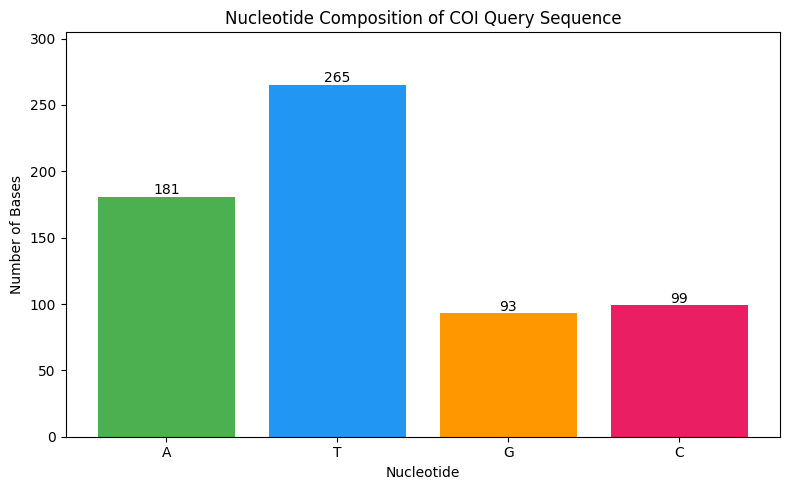

Nucleotide composition figure saved!


In [ ]:

import matplotlib.pyplot as plt

# Prepare nucleotide composition data
nucleotides = ["A", "T", "G", "C"]
values = [A, T, G, C]

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    nucleotides,
    values,
    color=["#4CAF50", "#2196F3", "#FF9800", "#E91E63"]
)

# Add nucleotide counts above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        str(int(height)),
        ha="center"
    )

# Chart labels
plt.title("Nucleotide Composition of COI Query Sequence")
plt.xlabel("Nucleotide")
plt.ylabel("Number of Bases")

plt.ylim(0, max(values) * 1.15)
plt.tight_layout()

# Save figure
plt.savefig(
    project_dir / "results/nucleotide_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Nucleotide composition figure saved!")



### 4.3 Sequence Summary Table

**Objective:**
Create a reproducible summary table containing
sequence length, nucleotide counts, GC content,
AT content, and ambiguous bases.

The results are exported as a CSV file
for subsequent analysis and documentation.

In [ ]:

import pandas as pd

# Create sequence summary table
summary = pd.DataFrame([{
    "Sequence_ID": sequence.id,
    "Length_bp": length,
    "A": A,
    "T": T,
    "G": G,
    "C": C,
    "GC_Content_Percent": round(gc_content, 2),
    "AT_Content_Percent": round(at_content, 2),
    "Ambiguous_Bases": ambiguous
}])

# Display results
print("=== COI SEQUENCE SUMMARY ===")
display(summary)

# Save table as CSV
summary.to_csv(
    project_dir / "results/sequence_summary.csv",
    index=False
)

print("Sequence summary saved successfully!")


=== COI SEQUENCE SUMMARY ===


,Sequence_ID,Length_bp,A,T,G,C,GC_Content_Percent,AT_Content_Percent,Ambiguous_Bases
0,Unknown_Insect_01,638,181,265,93,99,30.09,69.91,0


Sequence summary saved successfully!



## 5. Molecular Species Identification Using BLASTn

### 5.1 Query Sequence Preparation

**Objective:**
Prepare the uploaded mitochondrial COI sequence
for species identification using NCBI BLASTn.

**Methods:**
- Retrieve the uploaded query sequence.
- Verify its FASTA format.
- Prepare the sequence for BLASTn analysis.

**Query Information:**
- Sequence ID: Unknown_Insect_01
- Gene: Cytochrome c oxidase subunit I (COI)
- Sequence length: 638 bp

**Note:**
The query is a simulated unknown sequence
derived from GenBank accession MF197868.1.


In [ ]:

from Bio import SeqIO
from google.colab import files

# Read the uploaded query sequence
query_file = project_dir / "data" / "query_coi.fasta"

query = SeqIO.read(query_file, "fasta")

print("=== BLAST QUERY INFORMATION ===")
print("Query ID:", query.id)
print("Sequence length:", len(query.seq), "bp")
print("Sequence ready for BLASTn!")

# Download FASTA for NCBI BLAST upload
files.download(str(query_file))


=== BLAST QUERY INFORMATION ===
Query ID: Unknown_Insect_01
Sequence length: 638 bp
Sequence ready for BLASTn!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### 5.5 BLAST Results Analysis Using Python

**Objective:**
Analyze BLASTn results to identify the most
similar reference sequences to the unknown
insect COI query.

**Methods:**
- Import the BLAST hit table (CSV).
- Assign column names.
- Examine sequence similarity.
- Identify the best matching references.

**Expected Output:**
A table containing BLAST sequence similarity
results for molecular species identification.


In [ ]:

import pandas as pd
from google.colab import files
from io import BytesIO

# Upload BLAST Hit Table CSV
uploaded = files.upload()
filename = next(iter(uploaded))

# Column names for BLAST tabular output
columns = [
    "Query_ID",
    "Subject_ID",
    "Percent_Identity",
    "Alignment_Length",
    "Mismatches",
    "Gap_Opens",
    "Query_Start",
    "Query_End",
    "Subject_Start",
    "Subject_End",
    "E_Value",
    "Bit_Score"
]

# Read BLAST CSV without header
blast = pd.read_csv(
    BytesIO(uploaded[filename]),
    header=None,
    names=columns
)

print("=== BLAST RESULTS ===")
print("Total BLAST hits:", len(blast))

display(blast.head(10))

Saving DPB2YK3J014-Alignment-HitTable.csv to DPB2YK3J014-Alignment-HitTable (4).csv
=== BLAST RESULTS ===
Total BLAST hits: 100


,Query_ID,Subject_ID,Percent_Identity,Alignment_Length,Mismatches,Gap_Opens,Query_Start,Query_End,Subject_Start,Subject_End,E_Value,Bit_Score
0,Unknown_Insect_01,OR347321.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
1,Unknown_Insect_01,OR347314.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
2,Unknown_Insect_01,OR347423.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
3,Unknown_Insect_01,OR347315.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
4,Unknown_Insect_01,OR347300.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
5,Unknown_Insect_01,OR347298.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
6,Unknown_Insect_01,OR347227.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
7,Unknown_Insect_01,OR347219.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
8,Unknown_Insect_01,OR347221.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
9,Unknown_Insect_01,OR347204.1,100.0,638,0,0,1,638,1528,2165,0.0,1179



### 5.6 Best BLAST Match Identification

**Objective:**
Identify the most similar reference sequences
based on sequence identity, query coverage,
and alignment bit score.

**Methods:**
- Calculate query coverage.
- Sort BLAST hits by similarity.
- Display the top five reference matches.
- Export the results as a CSV file.


In [ ]:

# Convert relevant columns to numeric
numeric_columns = [
    "Percent_Identity",
    "Alignment_Length",
    "Query_Start",
    "Query_End",
    "E_Value",
    "Bit_Score"
]

blast[numeric_columns] = blast[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Calculate query coverage
query_length = len(sequence.seq)

blast["Query_Coverage"] = (
    (blast["Query_End"] - blast["Query_Start"]).abs() + 1
) / query_length * 100

# Sort by best matches
best_hits = blast.sort_values(
    by=["Bit_Score", "Query_Coverage",
        "Percent_Identity"],
    ascending=False
)

# Display top five
top5 = best_hits.head(5)

print("=== TOP 5 BLAST MATCHES ===")

display(
    top5[
        [
            "Subject_ID",
            "Percent_Identity",
            "Query_Coverage",
            "E_Value",
            "Bit_Score"
        ]
    ].round(2)
)

# Save results
top5.to_csv(
    project_dir / "results/blast_top5_matches.csv",
    index=False
)

print("Top 5 BLAST matches saved!")


=== TOP 5 BLAST MATCHES ===


,Subject_ID,Percent_Identity,Query_Coverage,E_Value,Bit_Score
0,OR347321.1,100.0,100.0,0.0,1179
1,OR347314.1,100.0,100.0,0.0,1179
2,OR347423.1,100.0,100.0,0.0,1179
3,OR347315.1,100.0,100.0,0.0,1179
4,OR347300.1,100.0,100.0,0.0,1179


Top 5 BLAST matches saved!



### 5.7 Species Identification Summary

**Objective:**
Identify the candidate insect species by retrieving
taxonomic information from the top BLAST matches.

**Methods:**
- Retrieve reference metadata from NCBI GenBank.
- Extract scientific names.
- Combine taxonomic information with BLAST results.
- Generate a species identification summary.

**Expected Output:**
A table showing the top BLAST matches and their
corresponding scientific names.


In [ ]:

from Bio import Entrez, SeqIO
import pandas as pd

# Use the NCBI email configured earlier
# Entrez.email should contain your valid email

accessions = top5["Subject_ID"].tolist()

# Retrieve taxonomic information
with Entrez.efetch(
    db="nuccore",
    id=",".join(accessions),
    rettype="gb",
    retmode="text"
) as handle:
    records = list(SeqIO.parse(handle, "genbank"))

# Build accession-to-species mapping
species_lookup = {
    rec.id: rec.annotations.get("organism", "Unknown")
    for rec in records
}

# Add scientific names
identification_table = top5.copy()

identification_table["Scientific_Name"] = (
    identification_table["Subject_ID"]
    .map(species_lookup)
)

# Display relevant columns
print("=== SPECIES IDENTIFICATION SUMMARY ===")

display(
    identification_table[
        [
            "Subject_ID",
            "Scientific_Name",
            "Percent_Identity",
            "Query_Coverage",
            "E_Value"
        ]
    ]
)

# Save results
identification_table.to_csv(
    project_dir / "results/species_identification_summary.csv",
    index=False
)

print("Species identification summary saved!")


=== SPECIES IDENTIFICATION SUMMARY ===


,Subject_ID,Scientific_Name,Percent_Identity,Query_Coverage,E_Value
0,OR347321.1,Spodoptera frugiperda,100.0,100.0,0.0
1,OR347314.1,Spodoptera frugiperda,100.0,100.0,0.0
2,OR347423.1,Spodoptera frugiperda,100.0,100.0,0.0
3,OR347315.1,Spodoptera frugiperda,100.0,100.0,0.0
4,OR347300.1,Spodoptera frugiperda,100.0,100.0,0.0


Species identification summary saved!


## 6. Simple Phylogenetic Tree Construction

### 6.1 Comparative COI Phylogeny

**Objective:**
Construct a simple phylogenetic tree to compare the
query insect COI sequence with representative COI
references from related and non-related pest species.

**Reference Species:**
- Spodoptera frugiperda
- Spodoptera litura
- Spodoptera exigua
- Helicoverpa armigera
- Ostrinia furnacalis

**Methods:**
- Retrieve representative COI sequences from NCBI
- Combine them with the query sequence
- Align the sequences
- Build a phylogenetic tree

In [ ]:
from Bio import Entrez, SeqIO
from Bio.SeqRecord import SeqRecord
from pathlib import Path

# pastikan email sudah diisi
Entrez.email = "dsintapramudita@gmail.com"

# query sequence
query_file = project_dir / "data" / "query_coi.fasta"
query_record = SeqIO.read(query_file, "fasta")
query_record.id = "Query_S_frugiperda"
query_record.name = "Query_S_frugiperda"
query_record.description = "Query sequence"

target_species = [
    "Spodoptera frugiperda",
    "Spodoptera litura",
    "Spodoptera exigua",
    "Helicoverpa armigera",
    "Ostrinia furnacalis"
]

def extract_coi_sequence(record):
    """
    Extract COI/COX1 region from GenBank feature if available.
    If no feature found, return full sequence.
    """
    for feat in record.features:
        if feat.type in ["gene", "CDS"]:
            genes = [g.lower() for g in feat.qualifiers.get("gene", [])]
            products = " ".join(feat.qualifiers.get("product", [])).lower()

            if (
                "coi" in genes or
                "co1" in genes or
                "cox1" in genes or
                "cytochrome c oxidase subunit i" in products
            ):
                seq = feat.extract(record.seq)
                return seq

    return record.seq

def fetch_reference_coi(species_name):
    term = (
        f'"{species_name}"[Organism] AND '
        f'("cytochrome c oxidase subunit I"[Title] OR COI[Title] OR CO1[Title] OR cox1[Title])'
    )

    with Entrez.esearch(db="nucleotide", term=term, retmax=10) as handle:
        search_result = Entrez.read(handle)

    ids = search_result["IdList"]
    if not ids:
        raise ValueError(f"No NCBI records found for {species_name}")

    with Entrez.efetch(db="nucleotide", id=",".join(ids), rettype="gb", retmode="text") as handle:
        records = list(SeqIO.parse(handle, "genbank"))

    for rec in records:
        coi_seq = extract_coi_sequence(rec)
        coi_seq = str(coi_seq).upper().replace("-", "")

        if 500 <= len(coi_seq) <= 2000:
            short_name = species_name.replace(" ", "_")
            return SeqRecord(
                seq=rec.seq.__class__(coi_seq),
                id=short_name,
                name=short_name,
                description=f"{species_name} | source accession: {rec.id}"
            )

    raise ValueError(f"No suitable COI sequence found for {species_name}")

reference_records = []
for sp in target_species:
    ref = fetch_reference_coi(sp)
    reference_records.append(ref)
    print(f"Retrieved: {ref.id} | length = {len(ref.seq)} bp")

# combine query + references
all_records = [query_record] + reference_records

combined_fasta = project_dir / "data" / "phylo_species_comparison.fasta"
SeqIO.write(all_records, combined_fasta, "fasta")

print("\nCombined FASTA saved to:", combined_fasta)
print("Total sequences:", len(all_records))

Retrieved: Spodoptera_frugiperda | length = 590 bp
Retrieved: Spodoptera_litura | length = 679 bp
Retrieved: Spodoptera_exigua | length = 675 bp
Retrieved: Helicoverpa_armigera | length = 658 bp
Retrieved: Ostrinia_furnacalis | length = 641 bp

Combined FASTA saved to: /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification/data/phylo_species_comparison.fasta
Total sequences: 6


In [ ]:

import pandas as pd

reference_check = pd.DataFrame([
    {
        "Species": rec.id,
        "Accession": rec.description.split(
            "source accession: "
        )[-1] if "source accession: " in rec.description
        else "Not recorded",
        "Length_bp": len(rec.seq),
        "Ambiguous_Bases": sum(
            base.upper() not in "ATGC"
            for base in str(rec.seq)
        )
    }
    for rec in reference_records
])

print("=== SELECTED COI REFERENCE ACCESSIONS ===")
display(reference_check)


=== SELECTED COI REFERENCE ACCESSIONS ===


,Species,Accession,Length_bp,Ambiguous_Bases
0,Spodoptera_frugiperda,QB058493.1,590,0
1,Spodoptera_litura,QB146085.1,679,0
2,Spodoptera_exigua,PZ956218.1,675,0
3,Helicoverpa_armigera,PZ902906.1,658,0
4,Ostrinia_furnacalis,PX558621.1,641,0


In [ ]:
print("=== PHYLOGENETIC DATASET ===")
for rec in all_records:
    print(rec.id, "|", len(rec.seq), "bp")

=== PHYLOGENETIC DATASET ===
Query_S_frugiperda | 638 bp
Spodoptera_frugiperda | 590 bp
Spodoptera_litura | 679 bp
Spodoptera_exigua | 675 bp
Helicoverpa_armigera | 658 bp
Ostrinia_furnacalis | 641 bp


In [ ]:

import shutil

print("iqtree:", shutil.which("iqtree"))
print("iqtree2:", shutil.which("iqtree2"))

iqtree: None
iqtree2: /usr/bin/iqtree2


### 6.2 Multiple Sequence Alignment

The query and reference COI sequences were aligned
using MAFFT prior to phylogenetic analysis.

In [ ]:
aligned_fasta = project_dir / "data" / "phylo_species_comparison_aligned.fasta"

!mafft --auto "{combined_fasta}" > "{aligned_fasta}"

print("Aligned FASTA saved to:", aligned_fasta)

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
generating a scoring matrix for nucleotide (dist=200) ... done
All-to-all alignment.
tbfast-pair (nuc) Version 7.505
alg=L, model=DNA200 (2), 2.00 (6.00), -0.10 (-0.30), noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
generating a scoring matrix for nucleotide (dist=200) ... done
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
    0 / 6
done.

Progressive alignment ... 
STEP     5 /5 
done.
tbfast (nuc) Version 7.505
alg=A, model=DNA200 (2), 1.53 (4.59), -0.00 (-0.00), noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
generating a scoring matrix for nucleotide (dist=200) ... done

    0 / 6
Segment   1/  1    1- 681
STEP 002-004-1  identical.   
Conver

### 6.3 Phylogenetic Tree Construction

A simple maximum-likelihood phylogenetic tree
was constructed using IQ-TREE with the HKY model
and 1,000 ultrafast bootstrap replicates.

In [ ]:
iqtree_exe = (
    shutil.which("iqtree2")
    or shutil.which("iqtree")
)

In [ ]:

import subprocess
import shutil

# Find IQ-TREE executable
iqtree_exe = (
    shutil.which("iqtree2")
    or shutil.which("iqtree")
)

if iqtree_exe is None:
    raise RuntimeError(
        "IQ-TREE is not installed. "
        "Please install IQ-TREE first."
    )

# Output directory
tree_prefix = project_dir / "results" / "simple_phylogeny"

# Run IQ-TREE
command = [
    iqtree_exe,
    "-s", str(aligned_fasta),
    "-m", "HKY",
    "-bb", "1000",
    "-bnni",
    "-redo",
    "-pre", str(tree_prefix)
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-2000:])
print(result.stderr[-2000:])

if result.returncode != 0:
    raise RuntimeError("IQ-TREE analysis failed")

print("Phylogenetic analysis completed!")


Return code: 0
or tree search: 3.496 sec (0h:0m:3s)
Wall-clock time used for tree search: 3.609 sec (0h:0m:3s)
Total CPU time used: 3.548 sec (0h:0m:3s)
Total wall-clock time used: 3.716 sec (0h:0m:3s)
UFBoot trees printed to /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification/results/simple_phylogeny.ufboot

Computing bootstrap consensus tree...
Reading input file /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification/results/simple_phylogeny.splits.nex...
6 taxa and 14 splits.
Consensus tree written to /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification/results/simple_phylogeny.contree
Reading input trees file /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification/results/simple_phylogeny.contree
Log-likelihood of consensus tree: -1682.690

Analysis results written to: 
  IQ-TREE report:                /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identifi


### 6.7 Phylogenetic Tree Visualization

**Objective:**
Visualize the maximum-likelihood phylogenetic
relationships among six mitochondrial COI sequences.

**Methods:**
- Import the IQ-TREE Newick tree.
- Visualize phylogenetic relationships.
- Display ultrafast bootstrap support values.
- Export the tree as a high-resolution image.

**Species:**
- Spodoptera frugiperda (Query)
- Spodoptera frugiperda (Reference)
- Spodoptera litura
- Spodoptera exigua
- Helicoverpa armigera
- Ostrinia furnacalis


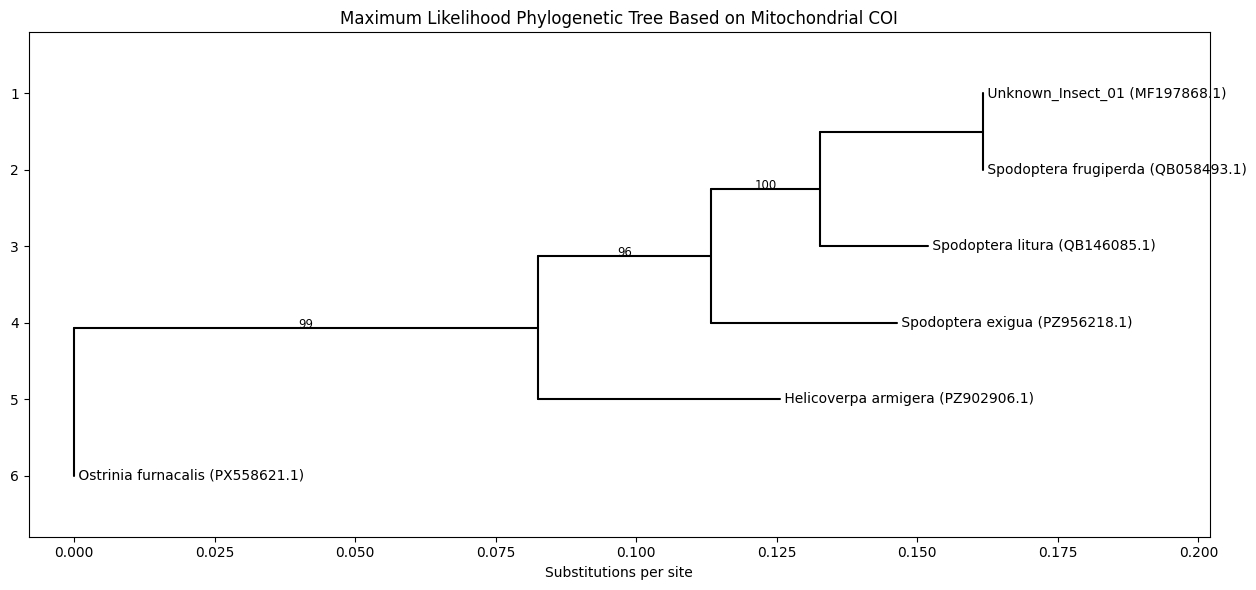

Rooted phylogenetic tree saved!


In [ ]:

from Bio import Phylo
import matplotlib.pyplot as plt
from pathlib import Path

# Read the phylogenetic tree
tree_file = Path(str(tree_prefix) + ".treefile")
tree = Phylo.read(tree_file, "newick")

# Root the tree using Ostrinia furnacalis
outgroup = next(
    tip for tip in tree.get_terminals()
    if tip.name == "Ostrinia_furnacalis"
)

tree.root_with_outgroup(outgroup)

# Create labels with accession numbers
label_map = {
    "Query_S_frugiperda":
        "Unknown_Insect_01 (MF197868.1)"
}

for rec in reference_records:
    accession = rec.description.split(
        "source accession: "
    )[-1]

    species = rec.id.replace("_", " ")
    label_map[rec.id] = f"{species} ({accession})"

# Visualize rooted tree
fig, ax = plt.subplots(figsize=(13, 6))

Phylo.draw(
    tree,
    axes=ax,
    do_show=False,
    show_confidence=True,
    label_func=lambda clade: (
        label_map.get(clade.name, clade.name)
        if clade.is_terminal() else None
    )
)

ax.set_title(
    "Maximum Likelihood Phylogenetic Tree "
    "Based on Mitochondrial COI"
)

ax.set_xlabel("Substitutions per site")
ax.set_ylabel("")

plt.tight_layout()

# Save figure
output = (
    project_dir / "results" /
    "COI_rooted_phylogenetic_tree.png"
)

plt.savefig(
    output,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Rooted phylogenetic tree saved!")


## 6.8 Results and Interpretation

### 6.8.1 Molecular Species Identification

The mitochondrial COI query sequence (638 bp; GenBank accession MF197868.1) was analyzed using NCBI BLASTn.

The five highest-ranking BLAST matches were annotated as *Spodoptera frugiperda*, showing 100% sequence identity and 100% query coverage.

These results strongly support the identification of the query sequence as *S. frugiperda*.

### 6.8.2 Phylogenetic Analysis

A maximum-likelihood phylogenetic tree was constructed using mitochondrial COI sequences from six insect samples representing five species:

- *Spodoptera frugiperda* (query and reference)
- *Spodoptera litura*
- *Spodoptera exigua*
- *Helicoverpa armigera*
- *Ostrinia furnacalis*

The query sequence clustered with the *S. frugiperda* reference, consistent with the BLASTn identification results.

The phylogenetic tree showed high ultrafast bootstrap support values (100, 96, and 99) for the displayed internal branches under the HKY substitution model.

### 6.8.3 Biological Interpretation

The results demonstrate the application of mitochondrial COI DNA barcoding for reference-based insect species identification.

The close phylogenetic placement of the query and *S. frugiperda* reference supports their genetic similarity within the analyzed COI region.

The other insect species provide comparative taxonomic context for evaluating the placement of the query sequence.

### 6.8.4 Limitations

This analysis used a publicly available GenBank sequence (MF197868.1) as a simulated unknown sample rather than a newly sequenced specimen.

The phylogenetic reconstruction included a limited number of reference sequences. The homologous COI overlap and reference suitability require further verification before definitive evolutionary conclusions can be drawn.

The maximum-likelihood tree was inferred using the HKY substitution model and visualized with *Ostrinia furnacalis* designated as the outgroup. The analysis remains exploratory because the suitability and homologous overlap of the selected COI reference sequences require further verification.

### 6.8.5 Conclusion

The combination of NCBI BLASTn and comparative COI phylogenetic analysis supports *Spodoptera frugiperda* as the candidate identity of the query sequence.

This project demonstrates a Python-based molecular identification workflow involving sequence assessment, database similarity searching, reference sequence comparison, multiple sequence alignment, and phylogenetic visualization.